#Dataset Dados Abertos STJ - Íntegras de Decisões Terminativas e Acórdãos do Diário da Justiça (Decisões)

##Experimento 08: Realizando curva de convergência durante treinamento do modelo.

##Importação de bibliotecas e declaração de variáveis globais

In [1]:
import torch

# Check if a GPU (CUDA) is available
if torch.cuda.is_available():
    print("GPU is available!")
    print("Device Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available, using CPU.")

# This is the line you'd use in your script to send your model or data to the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

GPU is available!
Device Name: Tesla V100S-PCIE-32GB
Using device: cuda


In [2]:
import pandas as pd

# Define the base path to the dataset folder
base_path = 'dataset/'
install_evaluate = False

EPOCHS = 150
APPROACH_EXECUTION = 'epoch' # 'step'

###Carregar classe/rótulo para a decisão (Favorável ou Não ao Réu)

In [3]:
# Define file paths
file_path = base_path + 'descricao-decisao-julgamento.csv'

# Load each CSV file into a dataframe
try:
    dfTipoDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfTipoDecisao'")
    display(dfTipoDecisao.head())
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded dataset/descricao-decisao-julgamento.csv into dataframe 'dfTipoDecisao'


,COD_TEOR_DECISAO,DESC_TEOR_DECISAO,DESC_RSULT_JGTO,RESULTADO_RESUMIDO,DECISAO_FAVORAVEL
0,1,Concedendo,"AGRAVO CONHECIDO EM PARTE E, NESSA PARTE, PROVIDO",PARCIALMENTE CONHECIDO E PROVIDO,S
1,1,Concedendo,Agravo regimental provido,PROVIDO,S
2,1,Concedendo,CONCEDENDO HABEAS CORPUS,CONCEDIDO,S
3,1,Concedendo,CONCEDENDO HABEAS DATA,CONCEDIDO,S
4,1,Concedendo,CONCEDENDO MANDADO DE SEGURANÇA,CONCEDIDA,S


##Carregar metadados das decisões (Documento, Processo, Nro de Registro, Ministro, Teor).

In [4]:
file_path = base_path + 'metadados-decisoes-acordaos-dj052025.csv'

try:
    dfMetaDadosDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfMetaDadosDecisao'")
    display(dfMetaDadosDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded dataset/metadados-decisoes-acordaos-dj052025.csv into dataframe 'dfMetaDadosDecisao'


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


##Carregar detalhes das decisões

In [5]:
# Define file paths
file_path = base_path + 'decisoes-acordaos-dj052025.csv'

try:
    dfDetalheDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfDetalheDecisoes'")
    display(dfDetalheDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded dataset/decisoes-acordaos-dj052025.csv into dataframe 'dfDetalheDecisoes'


,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


In [6]:
dfMetaDadosDecisao.shape

(48588, 12)

In [7]:
dfDetalheDecisao.shape

(48027, 6)

##Tratamento dos dados
###Exclusão de campos desnecessários

In [8]:
dfMetaDadosDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48588 entries, 0 to 48587
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   SEQDOCUMENTO          48588 non-null  int64 
 1   DATAPUBLICACAO        48588 non-null  object
 2   TIPODOCUMENTO         48588 non-null  object
 3   NUMEROREGISTRO        48588 non-null  int64 
 4   PROCESSO              48588 non-null  object
 5   DATARECEBIMENTO       48588 non-null  object
 6   DATADISTRIBUICAO      48588 non-null  object
 7   NM_MINISTRO           48588 non-null  object
 8   RECURSO               6200 non-null   object
 9   TEOR                  48588 non-null  object
 10  DESCRICAOMONOCRATICA  48588 non-null  object
 11  ASSUNTOS              48588 non-null  object
dtypes: int64(2), object(10)
memory usage: 4.4+ MB


In [9]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


In [10]:
dfMetaDadosDecisao.drop(columns=['DATAPUBLICACAO','TIPODOCUMENTO','DATARECEBIMENTO','DATADISTRIBUICAO','ASSUNTOS'], inplace=True)
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,PROCESSO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA
0,309631639,202000946481,TP 2695,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...
1,310378377,202400362531,AREsp 2562174,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...
2,309409286,202401080738,REsp 2132967,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...


In [11]:
dfDetalheDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48027 entries, 0 to 48026
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SEQDOCUMENTO  48027 non-null  int64  
 1   ACORDAO       0 non-null      float64
 2   EMENTA        13 non-null     object 
 3   RELATORIO     0 non-null      float64
 4   VOTO          0 non-null      float64
 5   DECISAO       48011 non-null  object 
dtypes: float64(3), int64(1), object(2)
memory usage: 2.2+ MB


In [12]:
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


In [13]:
dfDetalheDecisao.drop(columns=['ACORDAO', 'EMENTA', 'RELATORIO', 'VOTO'], inplace=True)
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,DECISAO
0,309631639,O presente pedido de contracautela tinha por o...
1,310378377,Trata-se de agravo em recurso especial interpo...
2,309409286,Trata-se de recurso especial interposto por MA...


##Redução dos registros com o intuito de reduzir o tempo no treinamento e verificar a curva de convergência

###Separar o número de processo pelo tipo (Aresp, HC).

In [14]:
#field = "AREsp 2562174".split(" ")
#print(f"Tipo: '{field[0]}' Processo: '{field[1]}'  ")

dfMetaDadosDecisao['TIPOPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda tipoprocesso: tipoprocesso.split(" ")[0])
dfMetaDadosDecisao['NUMEROPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda numeroprocesso: numeroprocesso.split(" ")[1])
dfMetaDadosDecisao.drop(columns=['PROCESSO'], inplace=True, axis=1)

dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967


In [15]:
dfMetaDadosDecisao['TIPOPROCESSO'].value_counts()

TIPOPROCESSO
AREsp         27718
HC             9123
REsp           6650
CC             1956
RHC            1534
RMS             349
EAREsp          309
Rcl             235
EREsp           122
CR              121
ExeMS            97
MS               89
PUIL             69
Pet              68
TutCautAnt       35
AR               29
TutAntAnt        23
RvCr             21
SLS               8
HD                7
Ag                6
TP                5
HDE               5
EmbExeMS          4
Prc               2
SS                2
ExeAR             1
Name: count, dtype: int64

In [16]:
# dfMetaDadosDecisao = dfMetaDadosDecisao[dfMetaDadosDecisao['TIPOPROCESSO'] == 'REsp']
# dfMetaDadosDecisao.head(3)

##Sanitização do campo DECISAO

###Remoção de TAG's HTML do campo DECISAO e substituição por espaço em branco

In [17]:
import re

def remove_html_tags(text):
    if isinstance(text, str):
        clean = re.compile('<.*?>')
        return re.sub(clean, ' ', text)
    return text

dfDetalheDecisao['DECISAO'] = dfDetalheDecisao['DECISAO'].apply(remove_html_tags)
display(dfDetalheDecisao.head())

,SEQDOCUMENTO,DECISAO
0,309631639,O presente pedido de contracautela tinha por o...
1,310378377,Trata-se de agravo em recurso especial interpo...
2,309409286,Trata-se de recurso especial interposto por MA...
3,310313783,Em agravo interposto contra decisão do Tribuna...
4,308791735,JOSIMAR TEOTONIO PONTES alega ser vítima de co...


###Remover STOP WORDS
Motivação: https://medium.com/turing-talks/ferramentas-para-processamento-de-linguagem-natural-em-portugu%C3%AAs-977c7f59c382

In [18]:
import nltk

nltk.download('stopwords')

stopwords = nltk.corpus.stopwords.words('portuguese')

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/alessandro.cporto/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [19]:
import re
import nltk

nltk.download('stopwords')

def pre_processamento(texto):
    # Ensure texto is a string before processing
    if not isinstance(texto, str):
        return "" # Return empty string or handle non-string as appropriate

    # seleciona apenas letras
    letras =  re.findall(r'\b[A-zÀ-úü]+\b', texto) # Pass the text to findall

    # remove stopwords
    stopwords = nltk.corpus.stopwords.words('portuguese')
    stop = set(stopwords)
    sem_stopwords = [w for w in letras if w.lower() not in stop] # Use lower() for case-insensitive stopword removal

    # juntando os tokens novamente em formato de texto
    texto_limpo = " ".join(sem_stopwords)

    return texto_limpo

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/alessandro.cporto/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [20]:
#Exemplo de uso da função
texto = """Trata-se dehabeas corpussubstitutivo de recurso próprio, com pedido de liminar, impetrado em favor deLUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo"""
texto = pre_processamento(texto)

print(texto)


Trata dehabeas corpussubstitutivo recurso próprio pedido liminar impetrado favor deLUIS FELIPE SILVA ASSIS aponta autoridade coatora Tribunal Justiça Estado Rio Janeiro Consta autos paciente condenado pena anos meses reclusão regime semiaberto pagamento dias multa incurso art caput c c VI Lei n sede recursal Tribunal origem negou provimento apelo defensivo


In [21]:
dfDetalheDecisao['DECISAO'] = dfDetalheDecisao['DECISAO'].apply(pre_processamento)

In [22]:
import re

def remove_extra_spaces(text):
    if isinstance(text, str):
        # Replace multiple whitespace characters (spaces, tabs, newlines) with a single space
        return re.sub(r'\s+', ' ', text).strip()
    return text

In [23]:
#Exemplo de uso da função
texto = """   Trata-se  dehabeas   corpussubstitutivo    de
recurso          próprio, com pedido de liminar."""
texto = remove_extra_spaces(texto)

print(texto)

Trata-se dehabeas corpussubstitutivo de recurso próprio, com pedido de liminar.


In [24]:
dfDetalheDecisao['DECISAO'] = dfDetalheDecisao['DECISAO'].apply(remove_extra_spaces)

###Junção dos Datasets em um único dataset

In [25]:
def get_decisao(seq_documento):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    decisao_row = dfDetalheDecisao[dfDetalheDecisao['SEQDOCUMENTO'] == seq_documento]

    # Check if the filtered DataFrame is empty
    if not decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return decisao_row.head(1)['DECISAO'].iloc[0]
    else:
        # If empty, return None
        return None

def get_tipo_decisao(teor_decisao):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    tipo_decisao_row = dfTipoDecisao[dfTipoDecisao['DESC_TEOR_DECISAO'] == teor_decisao].head(1)

    # Check if the filtered DataFrame is empty
    if not tipo_decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return tipo_decisao_row.head(1)['DECISAO_FAVORAVEL'].iloc[0]
    else:
        # If empty, return None
        return None

In [26]:
dfMetaDadosDecisao['DECISAO']  = dfMetaDadosDecisao['SEQDOCUMENTO'].apply(get_decisao)
dfMetaDadosDecisao['DECISAO_FAVORAVEL']  = dfMetaDadosDecisao['TEOR'].apply(get_tipo_decisao)

In [27]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695,presente pedido contracautela objeto suspensão...,N
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174,Trata agravo recurso especial interposto MIGUE...,N
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967,Trata recurso especial interposto MAYCKON SANT...,S


In [28]:
# Filter rows where 'TEOR' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao.dropna(subset=['TEOR']).copy()

# Filter rows where 'DECISAO' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO']).copy()

# Filter rows where 'DECISAO_FAVORAVEL is not empty (NaN) and assign to a new dataframe -- decisões neutras não possuem efeito jurídico considerável
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO_FAVORAVEL']).copy()

dfMetaDadosDecisao = dfMetaDadosDecisao_filtered
dfMetaDadosDecisao.head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695,presente pedido contracautela objeto suspensão...,N
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174,Trata agravo recurso especial interposto MIGUE...,N
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967,Trata recurso especial interposto MAYCKON SANT...,S
3,310313783,202403756009,CARLOS CINI MARCHIONATTI (DESEMBARGADOR CONVOC...,NaN,Não Conhecendo,Não conhecido o recurso de #{nome_da_parte} #{...,AREsp,2761478,agravo interposto contra decisão Tribunal Just...,N
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N


In [29]:
dfMetaDadosDecisao.head()

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695,presente pedido contracautela objeto suspensão...,N
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174,Trata agravo recurso especial interposto MIGUE...,N
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967,Trata recurso especial interposto MAYCKON SANT...,S
3,310313783,202403756009,CARLOS CINI MARCHIONATTI (DESEMBARGADOR CONVOC...,NaN,Não Conhecendo,Não conhecido o recurso de #{nome_da_parte} #{...,AREsp,2761478,agravo interposto contra decisão Tribunal Just...,N
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N


### Junção dos campos DESCRICAOMONOCRATICA com DECISAO
Estudar a possibilidade de dar maior atenção à decisão monocrática.

In [30]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695,presente pedido contracautela objeto suspensão...,N
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174,Trata agravo recurso especial interposto MIGUE...,N
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967,Trata recurso especial interposto MAYCKON SANT...,S


##Análise de dados após tratamento

In [31]:
dfMetaDadosDecisao['DECISAOCOMPLETA'] = dfMetaDadosDecisao['DESCRICAOMONOCRATICA'] + ' -- ' + dfMetaDadosDecisao['DECISAO']

###Verificando distribuição de dados entre as decisões favoráveis ou não ao réu

####Consulta direta no tipo de decisão (Favorável ou não)

In [32]:
#dfMetaDadosDecisao['DECISAOCOMPLETA'][283]

In [33]:
dfMetaDadosDecisao_filtered[dfMetaDadosDecisao_filtered['DECISAO_FAVORAVEL']  == 'N'].head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL,DECISAOCOMPLETA
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695,presente pedido contracautela objeto suspensão...,N,Prejudicada a ação de #{nome_da_parte} #{campo...
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174,Trata agravo recurso especial interposto MIGUE...,N,Conhecido o recurso de #{nome_da_parte} e não-...
3,310313783,202403756009,CARLOS CINI MARCHIONATTI (DESEMBARGADOR CONVOC...,NaN,Não Conhecendo,Não conhecido o recurso de #{nome_da_parte} #{...,AREsp,2761478,agravo interposto contra decisão Tribunal Just...,N,Não conhecido o recurso de #{nome_da_parte} #{...
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N,Denegado o Habeas Corpus de #{nome_da_parte} #...
5,310057660,202501165811,HERMAN BENJAMIN,NaN,Não Conhecendo,Não conhecido o recurso de #{nome_da_parte} #{...,AREsp,2899900,Cuida Agravo Recurso Especial apresentado LUCA...,N,Não conhecido o recurso de #{nome_da_parte} #{...


In [34]:
dfMetaDadosDecisao_filtered.shape

(48027, 11)

####Verificando distribuição dos dados propriamente dita

In [35]:
dataset = dfMetaDadosDecisao

total   = dataset.shape[0]
label_s = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 48027
LABEL S: 7402 - % 15.41
LABEL N: 40625 - % 84.59


##Preparação dos dados para Treinamento

###Separando entre dados de treinamento e teste

In [36]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = dataset.drop('DECISAO_FAVORAVEL', axis=1)
y = dataset['DECISAO_FAVORAVEL']

# Split the data into training and testing sets, stratifying by 'DECISAO_FAVORAVEL'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42, stratify=y)

print("Training set shape (X_train, y_train):", X_train.shape, y_train.shape)
print("Testing set shape (X_test, y_test):", X_test.shape, y_test.shape)

# Display the distribution of 'DECISAO_FAVORAVEL' in the original dataset, training set, and testing set
print("\nOriginal dataset 'DECISAO_FAVORAVEL' distribution:")
display(y.value_counts(normalize=True))

print("\nTraining set 'DECISAO_FAVORAVEL' distribution:")
display(y_train.value_counts(normalize=True))

print("\nTesting set 'DECISAO_FAVORAVEL' distribution:")
display(y_test.value_counts(normalize=True))

Training set shape (X_train, y_train): (31217, 10) (31217,)
Testing set shape (X_test, y_test): (16810, 10) (16810,)

Original dataset 'DECISAO_FAVORAVEL' distribution:


DECISAO_FAVORAVEL
N    0.845878
S    0.154122
Name: proportion, dtype: float64


Training set 'DECISAO_FAVORAVEL' distribution:


DECISAO_FAVORAVEL
N    0.845885
S    0.154115
Name: proportion, dtype: float64


Testing set 'DECISAO_FAVORAVEL' distribution:


DECISAO_FAVORAVEL
N    0.845866
S    0.154134
Name: proportion, dtype: float64

In [37]:
#dataframeGhost['gasper'] = 0

###Selecionando modelo pre-treinado e realizando tokenização

In [38]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification # Or BertTokenizer, BertForSequenceClassification

model_checkpoint = 'neuralmind/bert-base-portuguese-cased'

model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2) # Use AutoModelForSequenceClassification
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, do_lower_case=False)

2025-11-03 22:18:35.022545: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-03 22:18:36.639969: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-03 22:18:39.764703: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Some weights of BertForSequenceClassification were not initialized from the mode

In [39]:
from transformers import DataCollatorWithPadding
from datasets import Dataset # Import Dataset

# Pad to the longest sequence in the batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def preprocess_function(batches):
   """Tokenize input data"""
   return tokenizer(batches["DECISAO"], max_length=512, truncation=True) # Use "DECISAO" as the column name

# Convert pandas Series to Hugging Face Dataset
train_dataset = Dataset.from_pandas(X_train)
test_dataset = Dataset.from_pandas(X_test)

# Convert labels to integers
'''
The Hugging Face Trainer usually requires integer labels for classification.
I will convert the string labels ('S' and 'N') to integers (e.g., 0 and 1) before
adding them to the dataset.
'''
label_map = {'N': 0, 'S': 1}
y_train_encoded = y_train.map(label_map)
y_test_encoded = y_test.map(label_map)

# Add labels to the datasets
train_dataset = train_dataset.add_column("labels", y_train_encoded.tolist())
test_dataset = test_dataset.add_column("labels", y_test_encoded.tolist())

# Tokenize train/test data using the Dataset map method
tokenized_train = train_dataset.map(preprocess_function, batched=True)
tokenized_test = test_dataset.map(preprocess_function, batched=True)

Map:   0%|          | 0/31217 [00:00<?, ? examples/s]

Map:   0%|          | 0/16810 [00:00<?, ? examples/s]

In [40]:
#Show diferences between standard dataset and pandas dataset.
train_dataset['labels']

Column([1, 0, 0, 1, 0])

In [41]:
%%capture
if not install_evaluate:
  install_evaluate = True  
  %pip install evaluate

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


###Definindo método para averiguar a qualidade do modelo (métrica de avaliação)

In [42]:
import numpy as np
import evaluate

def compute_metrics(eval_pred):
    """Calculate F1 score"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    load_f1 = evaluate.load("f1")
    f1 = load_f1.compute(predictions=predictions, references=labels)["f1"]
    return {"f1": f1}

In [43]:
import sys

def get_avg_epoch_time(log_history: list) -> float | None:
    """
    Calcula o tempo médio por época (em minutos) a partir do 
    log_history do Hugging Face Trainer.

    Args:
        log_history (list): Uma lista de dicionários, que é o 
                            trainer.state.log_history.

    Returns:
        float: O tempo médio por época em minutos.
        None: Se os dados necessários não forem encontrados no histórico.
    """
    
    # 1. Encontrar o log de resumo do treino.
    #    Iteramos de trás para frente, pois o resumo é sempre um dos
    #    últimos itens logados.
    train_summary = None
    for log in reversed(log_history):
        if 'train_runtime' in log:
            train_summary = log
            break  # Encontramos o log que queremos

    # 2. Verificar se encontramos o log
    if train_summary is None:
        print("Erro: 'train_runtime' não foi encontrado no histórico de logs.", file=sys.stderr)
        return None

    # 3. Extrair os dados necessários
    # Usamos .get() para evitar erros caso a chave não exista
    total_seconds = train_summary.get('train_runtime')
    total_epochs = train_summary.get('epoch')

    # 4. Validar os dados
    if total_seconds is None or total_epochs is None:
        print("Erro: 'train_runtime' ou 'epoch' estão faltando no log de resumo.", file=sys.stderr)
        return None
        
    if total_epochs == 0:
        print("Erro: O número total de épocas é zero. Divisão por zero evitada.", file=sys.stderr)
        return None

    # 5. Calcular e retornar o tempo em minutos
    seconds_per_epoch = total_seconds / total_epochs
    minutes_per_epoch = seconds_per_epoch / 60
    
    return minutes_per_epoch

In [44]:
# X_train['Exception Please']

In [45]:
# # Print layer names
# i = 0
# for name, param in model.named_parameters():
#   i = i +1
#   print(f"index: {i} {name}")


In [46]:
# Encoder block 10 starts at index 165 and
# we freeze everything before that block
# for index, (name, param) in enumerate(model.named_parameters()):
#     if index < 165:
#         param.requires_grad = False

###Preparação do modelo

In [47]:
%%capture
!pip install tf_keras

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [48]:
# %%capture
# !pip install 'accelerate>=0.26.0'

In [49]:
# %%capture
# !pip install transformers[torch]

In [50]:
# This is the line that gets the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

Using device: cuda


In [51]:
from transformers import TrainingArguments, Trainer
import torch # Import torch

EPOCHS = 100
APPROACH_EXECUTION = 'epoch' 

# Training arguments for parameter tuning
if APPROACH_EXECUTION == 'epoch':
    training_args = TrainingArguments(
       "model",
       learning_rate= 2e-5,
       per_device_train_batch_size=16,
       per_device_eval_batch_size=16,
       num_train_epochs=EPOCHS,
       weight_decay=0.01,
       save_strategy="epoch",       
       logging_strategy="epoch",
       report_to="none",     
    )
else:#step
    training_args = TrainingArguments(
       "model",
       learning_rate= 1e-5,
       per_device_train_batch_size=32,
       per_device_eval_batch_size=32,
       num_train_epochs=EPOCHS,
       weight_decay=0.01,
       save_strategy="steps",              
       eval_steps=100, # Evaluate every 100 steps
       logging_steps=100, # Log every 100 steps
       report_to="none",  
       load_best_model_at_end=True, # Load the best model (based on metric) at the end of training 
       metric_for_best_model="f1", # Metric to monitor for best model selection
       greater_is_better=True, # A higher F1 score is better
    )

In [52]:
# Trainer which executes the training process
trainer = Trainer(
   model=model,
   args=training_args,
   train_dataset=tokenized_train,
   eval_dataset=tokenized_test,
   tokenizer=tokenizer,
   data_collator=data_collator,
   compute_metrics=compute_metrics,
)

/tmp/ipykernel_6533/2254602729.py:2: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


###Treinamento

In [53]:
import datetime
import time

def format_duration(td: datetime.timedelta) -> str:
    """Formata um objeto timedelta em HH:MM:SS."""
    total_seconds = int(td.total_seconds())
    hours = total_seconds // 3600
    minutes = (total_seconds % 3600) // 60
    seconds = total_seconds % 60
    # Retorna no formato 00:00:00
    return f"{hours:02}:{minutes:02}:{seconds:02}"

In [54]:
start_time = datetime.datetime.now()

start_time_str = start_time.strftime("%H:%M:%S")
print(f"✅ Processo iniciado em: {start_time_str}")

trainer.train()

end_time = datetime.datetime.now()
end_time_str = end_time.strftime("%H:%M:%S")
print(f"Processo finalizado em: {end_time_str}")

# --- 4. Calcular e imprimir a duração ---
duration = end_time - start_time

print("\n--- Resumo da Duração ---")
# Imprime o objeto timedelta (pode incluir microssegundos)
print(f"Duração (Objeto): {duration}")

# Imprime o total de segundos
print(f"Duração (Segundos): {duration.total_seconds():.2f} s")

# Imprime no formato HH:MM:SS
print(f"Duração (Formatada): {format_duration(duration)}")
print(f'Media de execucao por epoca: {round(get_avg_epoch_time(trainer.state.log_history),2) } min.')

✅ Processo iniciado em: 22:19:25


Step,Training Loss
1952,0.267100
3904,0.210400
5856,0.181500
7808,0.147700
9760,0.117600
11712,0.091900
13664,0.075400
15616,0.058600
17568,0.050300
19520,0.044600


Processo finalizado em: 00:04:51

--- Resumo da Duração ---
Duração (Objeto): 1 day, 1:45:26.419550
Duração (Segundos): 92726.42 s
Duração (Formatada): 25:45:26
Media de execucao por epoca: 15.45 min.


##Avaliação do modelo

In [65]:
trainer.state.log_history

[{'loss': 0.2671,
  'grad_norm': 0.015574636869132519,
  'learning_rate': 1.9800102459016396e-05,
  'epoch': 1.0,
  'step': 1952},
 {'loss': 0.2104,
  'grad_norm': 1.0180190801620483,
  'learning_rate': 1.9600102459016395e-05,
  'epoch': 2.0,
  'step': 3904},
 {'loss': 0.1815,
  'grad_norm': 0.02506890706717968,
  'learning_rate': 1.9400102459016393e-05,
  'epoch': 3.0,
  'step': 5856},
 {'loss': 0.1477,
  'grad_norm': 0.006199515890330076,
  'learning_rate': 1.9200102459016395e-05,
  'epoch': 4.0,
  'step': 7808},
 {'loss': 0.1176,
  'grad_norm': 0.10166281461715698,
  'learning_rate': 1.9000102459016394e-05,
  'epoch': 5.0,
  'step': 9760},
 {'loss': 0.0919,
  'grad_norm': 0.2278744876384735,
  'learning_rate': 1.8800102459016396e-05,
  'epoch': 6.0,
  'step': 11712},
 {'loss': 0.0754,
  'grad_norm': 0.001115457620471716,
  'learning_rate': 1.8600102459016397e-05,
  'epoch': 7.0,
  'step': 13664},
 {'loss': 0.0586,
  'grad_norm': 1.1645218133926392,
  'learning_rate': 1.8400102459016

In [56]:
###Salvar modelo para execucao 

In [57]:
import os

# Define the directory to save the model and tokenizer
output_dir = os.getcwd() + '/saved_model'

# Create the output directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Save the trained model
model.save_pretrained(output_dir)

# Save the tokenizer
tokenizer.save_pretrained(output_dir)

print(f"Model and tokenizer saved to {output_dir}")

Model and tokenizer saved to /home/alessandro.cporto/projeto_llm_pucpr/saved_model


###Curva de convergência

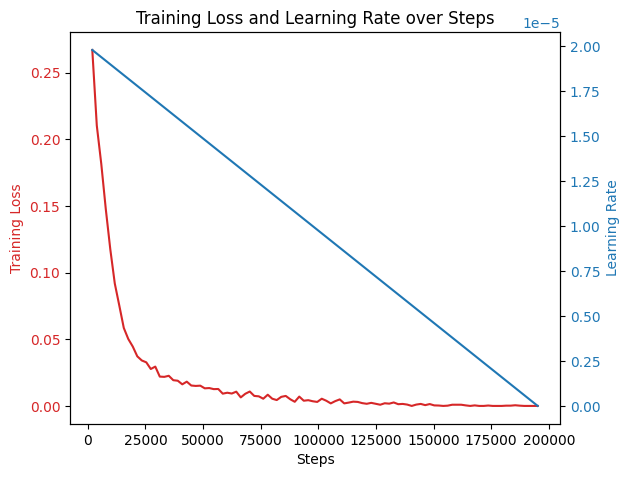

In [58]:
import matplotlib.pyplot as plt

# Get the training history
history = trainer.state.log_history

# Extract loss and learning rate values and steps
steps = []
loss_values = []
learning_rates = []

for entry in history:
    if 'loss' in entry:
        steps.append(entry['step'])
        loss_values.append(entry['loss'])
    if 'learning_rate' in entry:
        learning_rates.append(entry['learning_rate'])

# Ensure learning_rates list has the same length as steps/loss_values
# This might be necessary if learning_rate is not logged at every step
# A simple forward fill or interpolation could be used if needed,
# but for now, assume they are logged at similar intervals.
# If the lengths differ significantly, further investigation of the log history structure is needed.
# For this example, we'll assume they align closely or learning_rate entries are sufficient.
# A more robust approach would match steps between loss and learning_rate entries.

# Simple check: if lengths differ, we might need a more sophisticated approach
if len(steps) != len(learning_rates):
    print("Warning: Length of loss and learning rate entries in history differ.")
    # Depending on logging frequency, you might need to align these based on 'step'

# Plot the convergence curve and learning rate
fig, ax1 = plt.subplots()

color = 'tab:red'
ax1.set_xlabel('Steps')
ax1.set_ylabel('Training Loss', color=color)
ax1.plot(steps, loss_values, color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('Learning Rate', color=color)  # we already handled the x-label with ax1
ax2.plot(steps, learning_rates, color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.title('Training Loss and Learning Rate over Steps')
plt.show()

###Avaliação propriamenta dita

In [59]:
trainer.evaluate()

{'eval_loss': 1.0427323579788208,
 'eval_f1': 0.6962774957698815,
 'eval_runtime': 177.641,
 'eval_samples_per_second': 94.629,
 'eval_steps_per_second': 5.916,
 'epoch': 100.0}

###Matriz de Confusão

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Get predictions from the trainer
predictions = trainer.predict(tokenized_test)

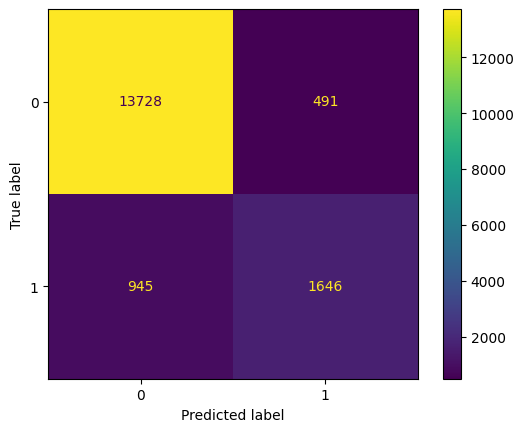

In [61]:
# Get the predicted labels
predicted_labels = np.argmax(predictions.predictions, axis=1)

# Get the true labels
true_labels = tokenized_test["labels"]

# Generate the confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Display the confusion matrix with desired label order
disp = ConfusionMatrixDisplay(confusion_matrix=cm,)
disp.plot()
plt.show()

###Curva ROC

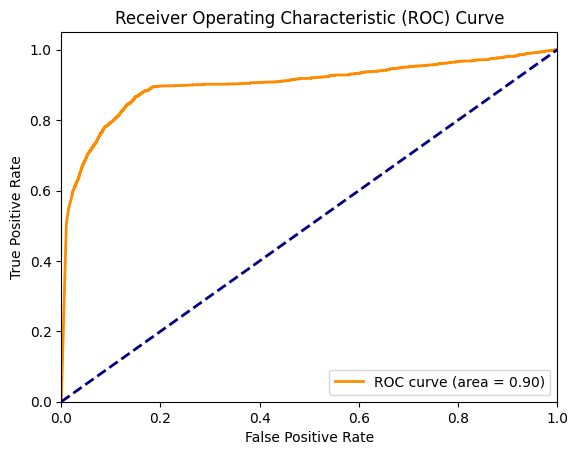

In [62]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc
from sklearn.metrics import roc_curve

# Get the prediction scores (probabilities) for the positive class
# For binary classification with logits, you typically apply a sigmoid or softmax
# Here, assuming logits, we'll take the exponent of the positive class logit
# If your model outputs probabilities directly, adjust this line
prediction_scores = np.exp(predictions.predictions[:, 1]) / np.sum(np.exp(predictions.predictions), axis=1)

# Get the true labels
true_labels = tokenized_test["labels"]

# Calculate the ROC curve points
fpr, tpr, thresholds = roc_curve(true_labels, prediction_scores)

# print("False Positive Rate (FPR):", fpr)
# print("True Positive Rate (TPR):", tpr)
# print("Thresholds:", thresholds)

# Calculate the Area Under the Curve (AUC)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import sys

def plot_training_history(log_history: list):
    """
    Processa o log_history do Hugging Face Trainer e plota os gráficos
    de perda (loss) e métricas de avaliação.

    Args:
        log_history (list): A lista de dicionários de trainer.state.log_history.
    """
    
    # 1. Separar logs de treino e avaliação
    train_logs = []
    eval_logs = []

    for log in log_history:
        if 'eval_loss' in log:
            # Este é um log de avaliação
            eval_logs.append(log)
        elif 'loss' in log:
            # Este é um log de treino (passo a passo)
            train_logs.append(log)
        # Ignoramos os logs de resumo final (ex: 'train_runtime')

    if not train_logs and not eval_logs:
        print("Histórico de log está vazio ou não contém logs de treino/avaliação.", file=sys.stderr)
        return

    # 2. Criar DataFrames
    train_df = pd.DataFrame(train_logs)
    eval_df = pd.DataFrame(eval_logs)

    # 3. Determinar o eixo X (preferir 'epoch', mas usar 'step' se 'epoch' não estiver)
    x_axis_train = 'epoch' if 'epoch' in train_df.columns else 'step'
    x_axis_eval = 'epoch' if 'epoch' in eval_df.columns else 'step'

    # 4. Encontrar a primeira métrica de avaliação (ex: 'eval_f1', 'eval_accuracy')
    metric_name = None
    if not eval_df.empty:
        for col in eval_df.columns:
            if col.startswith('eval_') and col not in ['eval_loss', 'eval_runtime', 
                                                       'eval_samples_per_second', 
                                                       'eval_steps_per_second']:
                metric_name = col
                break  # Encontramos a primeira métrica

    # 5. Criar os plots
    
    # Determinar quantos subplots precisamos
    num_plots = 1 + (1 if metric_name else 0)
    
    if num_plots == 2:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    else:
        fig, ax1 = plt.subplots(1, 1, figsize=(9, 6))
        ax2 = None # Sem segundo eixo

    # --- Gráfico 1: Perda (Loss) ---
    if not train_df.empty:
        ax1.plot(train_df[x_axis_train], train_df['loss'], label='Training Loss', alpha=0.7)
    if not eval_df.empty:
        ax1.plot(eval_df[x_axis_eval], eval_df['eval_loss'], label='Validation Loss', 
                 marker='o', markersize=5, linestyle='--')
    
    ax1.set_title('Training vs. Validation Loss')
    ax1.set_xlabel('Epoch' if x_axis_train == 'epoch' else 'Step')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, linestyle=':', alpha=0.6)

    # --- Gráfico 2: Métrica (se existir) ---
    if ax2 and metric_name:
        if not eval_df.empty:
            ax2.plot(eval_df[x_axis_eval], eval_df[metric_name], 
                     label=f'Validation {metric_name}', 
                     marker='o', markersize=5, linestyle='--', color='green')
        
        ax2.set_title(f'Validation Metric ({metric_name})')
        ax2.set_xlabel('Epoch' if x_axis_eval == 'epoch' else 'Step')
        ax2.set_ylabel(metric_name)
        ax2.legend()
        ax2.grid(True, linestyle=':', alpha=0.6)

    # Salvar e mostrar o gráfico
    plt.tight_layout()
    plot_filename = 'training_history.png'
    plt.savefig(plot_filename)
    
    print(f"✅ Gráficos de histórico de treino salvos em '{plot_filename}'")

✅ Gráficos de histórico de treino salvos em 'training_history.png'


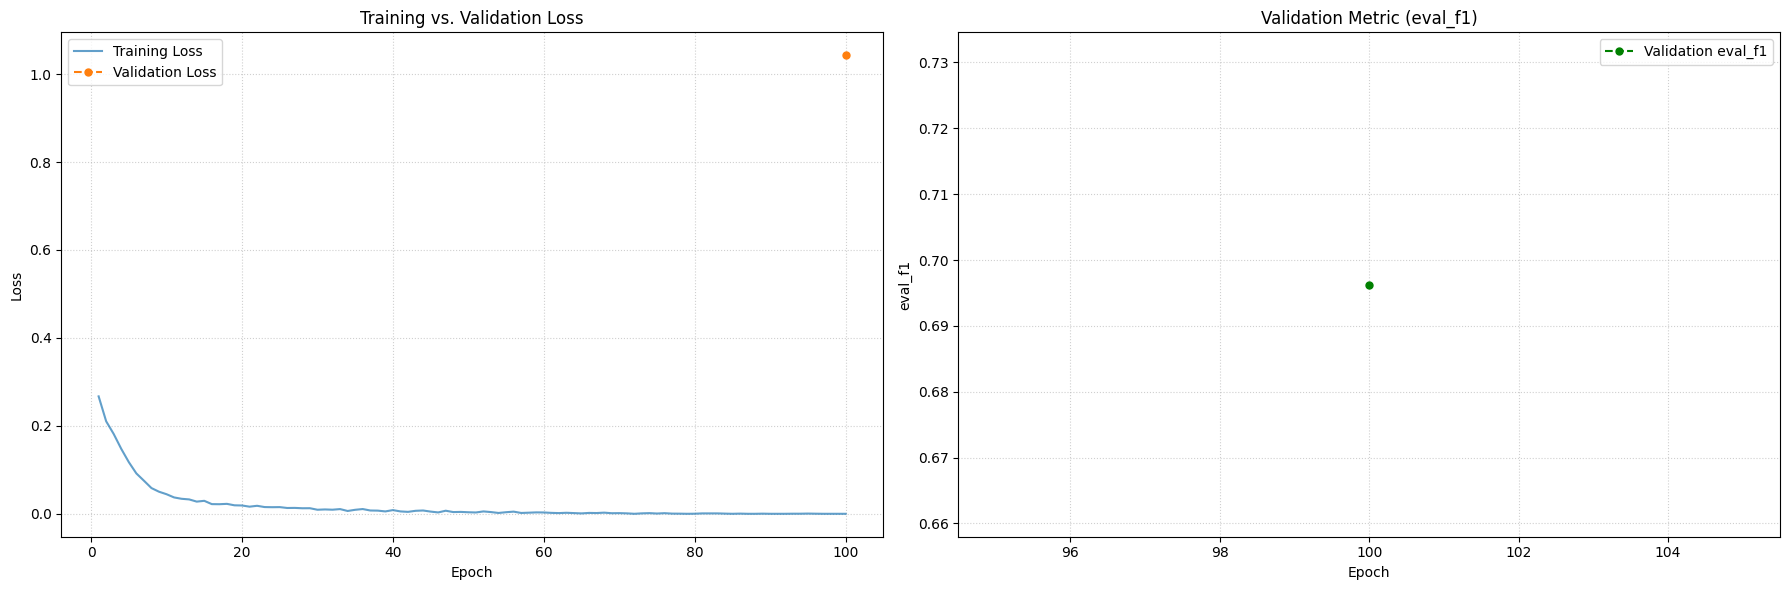

In [64]:
plot_training_history(trainer.state.log_history)